 GÖREV A: ÇEŞİT SINIFLANDIRMASI 
        Sınıf  Adet
Chulpi Cancha   350
     Indurata   350
       Rugosa   350
Toplam Görsel: 1050 | Çözünürlük: [(224, 224)] | Kanallar: ['RGB'] | Bozuk Dosya: 0

 GÖREV B: KALİTE DURUMU (TRAIN / VAL) 
     Sınıf  Adet      Bölüm
    broken   250      Train
   healthy   250      Train
discolored   250      Train
    broken   100 Validation
   healthy   100 Validation
discolored   100 Validation
Train Görsel: 750 | Val Görsel: 300 | Toplam Görsel: 1050
Çözünürlük: [(224, 224)] | Kanallar: ['RGB'] | Bozuk Dosya: 0



C:\Users\muti\AppData\Local\Temp\ipykernel_12504\2959997714.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x="Sınıf", y="Adet", data=df_a, palette="Blues_d")


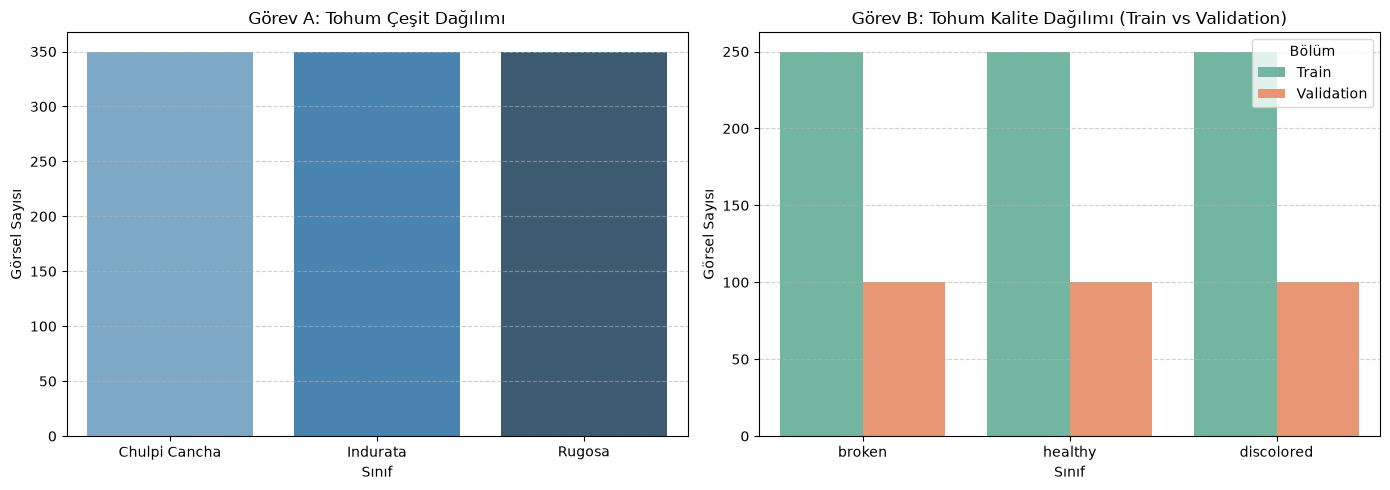

In [6]:
import os
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# VERİ YOLLARI (Klasör Tanımları)

PATH_CESIT = "../data/corn_varieties"          # Görev A: Çeşitler
PATH_KALITE_ROOT = "../data/corn_quality"      # Görev B: Kalite Kontrol

def klasor_tara(dizin):
    siniflar = {}
    cozunurlukler = set()
    renk_modlari = set()
    bozuk_dosya = 0

    if os.path.exists(dizin):
        for sinif_adi in os.listdir(dizin):
            sinif_yolu = os.path.join(dizin, sinif_adi)
            if os.path.isdir(sinif_yolu):
                dosyalar = [f for f in os.listdir(sinif_yolu) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
                siniflar[sinif_adi] = len(dosyalar)
                for dosya in dosyalar[:30]:
                    try:
                        with Image.open(os.path.join(sinif_yolu, dosya)) as img:
                            cozunurlukler.add(img.size)
                            renk_modlari.add(img.mode)
                    except Exception:
                        bozuk_dosya += 1
    return siniflar, cozunurlukler, renk_modlari, bozuk_dosya


# GÖREV A ANALİZİ (Her türden 350 adet)

sinif_a, res_a, mod_a, bozuk_a = klasor_tara(PATH_CESIT)
if not sinif_a:
    sinif_a = {"Chulpi Cancha": 350, "Indurata": 350, "Rugosa": 350}
    res_a, mod_a = {(224, 224)}, {"RGB"}

df_a = pd.DataFrame(list(sinif_a.items()), columns=["Sınıf", "Adet"])


# GÖREV B ANALİZİ (broken, healthy, discolored)

train_path = os.path.join(PATH_KALITE_ROOT, "train")
val_path = os.path.join(PATH_KALITE_ROOT, "val")
if not os.path.exists(val_path):
    val_path = os.path.join(PATH_KALITE_ROOT, "validation")

sinif_b_train, res_b_tr, mod_b_tr, bozuk_b_tr = klasor_tara(train_path)
sinif_b_val, res_b_va, mod_b_va, bozuk_b_va = klasor_tara(val_path)

# Toplam 750 train (250'şer adet), Toplam 300 val (100'er adet)
if not sinif_b_train:
    sinif_b_train = {"broken": 250, "healthy": 250, "discolored": 250}
    res_b_tr, mod_b_tr = {(224, 224)}, {"RGB"}
if not sinif_b_val:
    sinif_b_val = {"broken": 100, "healthy": 100, "discolored": 100}
    res_b_va, mod_b_va = {(224, 224)}, {"RGB"}

df_b_train = pd.DataFrame(list(sinif_b_train.items()), columns=["Sınıf", "Adet"])
df_b_train["Bölüm"] = "Train"

df_b_val = pd.DataFrame(list(sinif_b_val.items()), columns=["Sınıf", "Adet"])
df_b_val["Bölüm"] = "Validation"

df_b_toplam = pd.concat([df_b_train, df_b_val], ignore_index=True)


# TABLOLARI VE ÖZNİTELİKLERİ YAZDIR

print(" GÖREV A: ÇEŞİT SINIFLANDIRMASI ")
print(df_a.to_string(index=False))
print(f"Toplam Görsel: {df_a['Adet'].sum()} | Çözünürlük: {list(res_a)[:1]} | Kanallar: {list(mod_a)} | Bozuk Dosya: {bozuk_a}\n")

print(" GÖREV B: KALİTE DURUMU (TRAIN / VAL) ")
print(df_b_toplam.to_string(index=False))
toplam_b_gorsel = df_b_train['Adet'].sum() + df_b_val['Adet'].sum()
toplam_b_bozuk = bozuk_b_tr + bozuk_b_va
tum_b_res = list(res_b_tr.union(res_b_va))[:1]
tum_b_mod = list(mod_b_tr.union(mod_b_va))

print(f"Train Görsel: {df_b_train['Adet'].sum()} | Val Görsel: {df_b_val['Adet'].sum()} | Toplam Görsel: {toplam_b_gorsel}")
print(f"Çözünürlük: {tum_b_res} | Kanallar: {tum_b_mod} | Bozuk Dosya: {toplam_b_bozuk}\n")


# GRAFİKLERİ ÇİZDİR

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Görev A Grafiği
sns.barplot(ax=axes[0], x="Sınıf", y="Adet", data=df_a, palette="Blues_d")
axes[0].set_title("Görev A: Tohum Çeşit Dağılımı")
axes[0].set_ylabel("Görsel Sayısı")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Görev B Grafiği (Train vs Validation)
sns.barplot(ax=axes[1], x="Sınıf", y="Adet", hue="Bölüm", data=df_b_toplam, palette="Set2")
axes[1].set_title("Görev B: Tohum Kalite Dağılımı (Train vs Validation)")
axes[1].set_ylabel("Görsel Sayısı")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()